# PS- 1D: FNN for Sign Language MNIST Classification

Open this notebook with `PS- 1D` as the working folder and run the cells from top to bottom using a Python 3 kernel with TensorFlow, pandas, matplotlib, and scikit-learn installed. Both CSV files are loaded from this folder only.

Each image is already flattened into 784 pixels (28 x 28). The dataset labels have gaps, so `LabelEncoder` maps them to consecutive class IDs using the training labels.


In [19]:
# a. Import all necessary packages
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam


In [20]:
# b. Load the training and testing data from this folder
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Separate the 784 pixels and scale values from 0-255 to 0-1.
x_train = train.drop("label", axis=1).values.astype("float32") / 255.0
x_test = test.drop("label", axis=1).values.astype("float32") / 255.0

# Convert labels with gaps to consecutive class IDs.
encoder = LabelEncoder()
y_train = encoder.fit_transform(train["label"])
y_test = encoder.transform(test["label"])


In [ ]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = encoder.inverse_transform(y_train[:10])
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [21]:
# c. Define the FNN: 784 inputs, 128 hidden neurons, one output per class
model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(len(encoder.classes_), activation="softmax")
])
model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                     │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 24)                  │             792 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 244,984 (956.97 KB)

 Trainable params: 244,984 (956.97 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# d. Train the model using Adam
# Sparse categorical cross-entropy uses integer class labels directly.
model.compile(optimizer='adam',
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=11, batch_size=32, verbose=2)


Epoch 1/11
858/858 - 11s - 13ms/step - accuracy: 0.2848 - loss: 2.2043
Epoch 2/11
858/858 - 8s - 9ms/step - accuracy: 0.6119 - loss: 1.1407
Epoch 3/11
858/858 - 7s - 9ms/step - accuracy: 0.7759 - loss: 0.6458
Epoch 4/11
858/858 - 8s - 9ms/step - accuracy: 0.8590 - loss: 0.4015
Epoch 5/11
858/858 - 8s - 9ms/step - accuracy: 0.9162 - loss: 0.2502
Epoch 6/11
858/858 - 7s - 8ms/step - accuracy: 0.9326 - loss: 0.1975
Epoch 7/11
858/858 - 7s - 9ms/step - accuracy: 0.9456 - loss: 0.1648
Epoch 8/11
858/858 - 8s - 9ms/step - accuracy: 0.9610 - loss: 0.1203
Epoch 9/11
858/858 - 8s - 9ms/step - accuracy: 0.9566 - loss: 0.1290
Epoch 10/11
858/858 - 8s - 9ms/step - accuracy: 0.9867 - loss: 0.0470
Epoch 11/11
858/858 - 8s - 9ms/step - accuracy: 0.9592 - loss: 0.1304


In [23]:
# e. Evaluate the network on the testing data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")


Test loss: 1.4175
Test accuracy: 73.44%


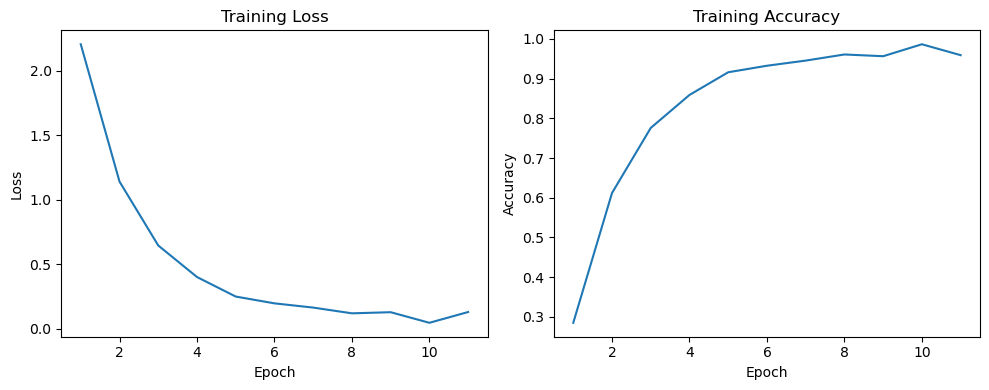

In [24]:
# f. Plot the training loss and accuracy
epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()
